In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import re
import os
import yaml
import tempfile
import shutil
import pickle
from tqdm import tqdm
from collections import Counter
from pathlib import Path
from typing import Dict, List, Optional, Tuple, Union

import numpy as np
import scanpy as sc
import pandas as pd
import anndata as ad

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

import torch
import torch.nn as nn
import torch.nn.functional as F
from collections import Counter

from datasets import Dataset, load_from_disk

# Ground-Truth vs Predicted Niches

In [4]:
base = "/nfs/team361/am84/TERRA/tasks/xhs_niche-transfer/model_artifacts/terra-zeroshot/outer-fold_1"
split_base = "/nfs/team361/am84/TERRA/tasks/xhs_niche-transfer/outer-fold_1"

train_features = np.load(f"{base}/train_features.npy")
train_labels = np.load(f"{base}/train_labels.npy")
test_features = np.load(f"{base}/test_features.npy")
test_cell_ids = np.load(f"{split_base}/test_cell_ids.npy", allow_pickle=True)

k = 20
batch_size = 10000  # matches knn_batch_size in the original zeroshot config

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tr_feat = F.normalize(torch.tensor(train_features, dtype=torch.float32, device=device), dim=1)
tr_lab = torch.tensor(train_labels, dtype=torch.long, device=device)

num_test = test_features.shape[0]
all_predictions = []

for start in range(0, num_test, batch_size):
  end = min(start + batch_size, num_test)
  batch_feat = F.normalize(
      torch.tensor(test_features[start:end], dtype=torch.float32, device=device), dim=1
  )
  similarity = torch.matmul(batch_feat, tr_feat.T)
  _, indices = similarity.topk(k, dim=1, largest=True, sorted=True)
  neighbor_labels = tr_lab[indices]

  batch_preds = torch.empty(end - start, dtype=tr_lab.dtype, device=device)
  for i in range(end - start):
      votes = Counter(neighbor_labels[i].tolist())
      batch_preds[i] = votes.most_common(1)[0][0]
  all_predictions.append(batch_preds.cpu())

  del similarity, neighbor_labels, batch_feat

predictions = torch.cat(all_predictions).numpy()

zsl_df = pd.DataFrame({
  "cell_id": test_cell_ids,
  "predicted_label": predictions,
})

In [5]:
def add_predicted_labels_to_adata(
    df: pd.DataFrame,
    adata: ad.AnnData,
    label_prefix: str = "niche19",
    predicted_label_col: str = "predicted_label",
    cell_id_col: str = "cell_id",
    output_col_name: str = None
) -> None:
    """
    Add predicted labels from a dataframe to an AnnData object.
    
    Parameters
    ----------
    df : pd.DataFrame
        DataFrame containing cell_id and predicted_label columns.
        predicted_label should be integers (0 to num_classes-1).
    adata : AnnData
        AnnData object containing test data with uns[f'{label_prefix}_idx2label'] mapping.
    label_prefix : str, default="niche19"
        Prefix for the label mapping in adata.uns. The function will look for
        adata.uns[f'{label_prefix}_idx2label'] which should map string keys like '0', '1', etc.
        to label names.
    predicted_label_col : str, default="predicted_label"
        Name of the column in df containing the predicted label indices.
    cell_id_col : str, default="cell_id"
        Name of the column in df containing cell IDs.
    output_col_name : str, optional
        Name of the output column in adata.obs. If None, defaults to f'zsl_{label_prefix}'.
    
    Returns
    -------
    None
        Modifies adata.obs in place by adding the predicted label column.
    """
    # Set default output column name
    if output_col_name is None:
        output_col_name = f'zsl_{label_prefix}'
    
    # Get the label mapping dictionary
    idx2label_key = f'{label_prefix}_idx2label'
    if idx2label_key not in adata.uns:
        raise KeyError(f"'{idx2label_key}' not found in adata.uns. Available keys: {list(adata.uns.keys())}")
    
    idx2label = adata.uns[idx2label_key]
    
    # Convert predicted_label indices to string labels using the mapping
    # Convert integer predicted_label to string key first, then map
    df = df.copy()  # Avoid modifying original dataframe
    df[output_col_name] = df[predicted_label_col].astype(str).map(idx2label)
    
    # Create a lookup dictionary from df indexed by cell_id
    label_lookup = df.set_index(cell_id_col)[output_col_name]
    
    # Match with adata.obs['cell_id'] and create the new column
    adata.obs[output_col_name] = adata.obs['cell_id'].map(label_lookup)
    
    # Log summary
    missing_count = adata.obs[output_col_name].isna().sum()
    total_count = len(adata.obs)
    print(f"Added '{output_col_name}' to adata.obs: {total_count - missing_count}/{total_count} cells matched")
    if missing_count > 0:
        print(f"Found {missing_count} cell_ids in adata.obs that are not in df")

In [10]:
# Canonical cell_ids for this outer fold, from the lightweight NFS split
# (the same source zsl_df's cell_id / test_features.npy rows are keyed to)
test_cell_ids = np.load(
  "/nfs/team361/am84/TERRA/tasks/xhs_niche-transfer/outer-fold_1/test_cell_ids.npy",
  allow_pickle=True
)

# Original full source adata (has expression, spatial, sample_id/dataset_id/batch,
# niche19 ground truth, but not the niche19 index<->label mapping used for zsl merge)
source_adata = sc.read_h5ad("/nfs/team361/am84/TERRA/data/xhs/xhs_harmonized_nemo_heldout.h5ad")

# Subset to exactly the canonical test cells for this fold, by cell_id (not by row position)
mask = source_adata.obs['cell_id'].isin(set(test_cell_ids))
test_adata = source_adata[mask].copy()
assert test_adata.n_obs == len(test_cell_ids), (
  f"Expected {len(test_cell_ids)} cells, got {test_adata.n_obs} -- "
  f"source adata and lightweight split have diverged."
)

# Pull the niche19 index<->label mapping (needed by add_predicted_labels_to_adata)
# from the pre-built full-format h5ad, without loading its expression matrix
_meta = sc.read_h5ad(
  "/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/xhs_niche-transfer/data/outer-fold_1/test.h5ad",
  backed='r'
)
test_adata.uns['niche19_idx2label'] = _meta.uns['niche19_idx2label']
test_adata.uns['niche19_label2idx'] = _meta.uns['niche19_label2idx']
test_adata.uns['niche19_colors'] = _meta.uns['niche19_colors']
del _meta

In [11]:
add_predicted_labels_to_adata(df=zsl_df, adata=test_adata, label_prefix="niche19", output_col_name="zsl_niche19")

Added 'zsl_niche19' to adata.obs: 265007/265007 cells matched


In [15]:
sample_ids = list(test_adata.obs['sample_id'].unique())
sample_id = sample_ids[1]  # pick whichever sample you want to visualize
select_adata = test_adata[test_adata.obs['sample_id'] == sample_id]

Filtered to top 10 labels: ['Small_BV', 'Epidermis_late', 'Epidermis_basal', 'Papillary_dermis', 'Reticular_dermis', 'Epidermis_mid', 'Muscle', 'Sweat_gland_channel', 'Reticular_dermis_LE_rich', 'Large_BV']
Remaining cells: 11129


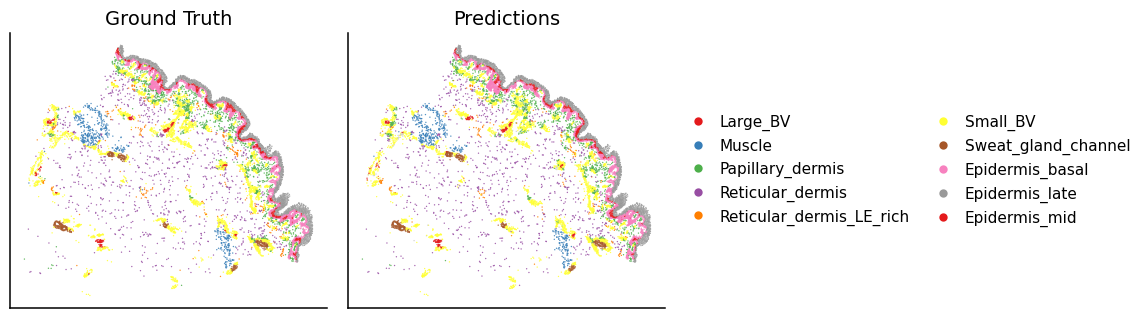

In [16]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import math
import seaborn as sns

# SET12_HEX = list(sns.color_palette("Set1", n_colors=15).as_hex()) + list(sns.color_palette("Set2", n_colors=15).as_hex())
SET1_HEX = list(sns.color_palette("Set1", n_colors=15).as_hex())

# ----------------------------
# Filter adata to top 10 labels by count
# ----------------------------

# # Filter adata to top 10 labels by count
# label_counts = select_adata.obs["niche19"].value_counts()
# top_10_labels = label_counts.head(10).index.tolist()

# # Filter to cells where BOTH ground truth AND prediction are in top 10
# adata = select_adata[
#     select_adata.obs["niche19"].isin(top_10_labels) & 
#     select_adata.obs["zsl_niche19"].isin(top_10_labels)
# ].copy()
label_counts = select_adata.obs["niche19"].value_counts()
top_10_labels = label_counts.head(10).index.tolist()
adata = select_adata[select_adata.obs["niche19"].isin(top_10_labels)].copy()

print(f"Filtered to top 10 labels: {top_10_labels}")
print(f"Remaining cells: {adata.n_obs}")

# ----------------------------
# Nature-style rcParams
# ----------------------------
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 14,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11,
    "axes.linewidth": 1.1,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})

# ----------------------------
# Data
# ----------------------------

coords = adata.obsm["spatial"]
x, y = coords[:, 0], coords[:, 1]

labels_gt = adata.obs["niche19"]
labels_pred = adata.obs["zsl_niche19"]

# Metadata from AnnData
idx2label = adata.uns["niche19_idx2label"]
colors = adata.uns["niche19_colors"]

# Filter labels_ordered to only include top 10 labels
labels_ordered = [label for label in idx2label.values() if label in top_10_labels]

# Create label_to_color mapping, using modulo to handle cases where there are more labels than colors
label_to_color = {
    label: SET1_HEX[i]
    for i, label in enumerate(labels_ordered)
}

# Convert categorical to string before mapping to avoid category issues
c_gt = labels_gt.astype(str).map(label_to_color).fillna("#cccccc")
c_pred = labels_pred.astype(str).map(label_to_color).fillna("#cccccc")

# ----------------------------
# Plot
# ----------------------------
fig, axes = plt.subplots(
    1, 2,
    figsize=(8.5, 4),
    sharex=True,
    sharey=True
)

POINT_SIZE = 1.0
ALPHA = 0.85

axes[0].scatter(
    x, y,
    c=c_gt,
    s=POINT_SIZE,
    linewidths=0,
    alpha=ALPHA,
    rasterized=True
)
axes[0].set_title("Ground Truth")

axes[1].scatter(
    x, y,
    c=c_pred,
    s=POINT_SIZE,
    linewidths=0,
    alpha=ALPHA,
    rasterized=True
)
axes[1].set_title("Predictions")

# ----------------------------
# Axis cleanup (despine)
# ----------------------------
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_aspect("equal")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# ----------------------------
# Legend (right, equal columns)
# ----------------------------
legend_labels = list(label_to_color.keys())

legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markerfacecolor=label_to_color[label],
        markeredgecolor="none",
        markersize=6,
        label=label
    )
    for label in legend_labels
]

n_labels = len(legend_handles)
n_cols = math.ceil(n_labels / 5)  # ~8 rows per column

fig.legend(
    handles=legend_handles,
    loc="center left",
    bbox_to_anchor=(0.8, 0.5),
    ncol=n_cols,
    frameon=False,
    title="",
    columnspacing=1.2,
    handletextpad=0.4
)

# ----------------------------
# Layout + save
# ----------------------------
plt.tight_layout(rect=[0, 0, 0.82, 1])

plt.savefig(
    "/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/figures/niche_transfer_visualize.svg",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
sample_ids = list(test_adata.obs['sample_id'].unique())
for i,sample_id in enumerate(sample_ids):
    select_adata = test_adata[test_adata.obs['sample_id'] == sample_id]
    print(i, select_adata.obs['niche19'].nunique(), select_adata.obs['zsl_niche19'].nunique(), select_adata.obs['lvl1_new'].nunique())
    print(select_adata.obs['niche19'].value_counts())
    print(select_adata.obs['zsl_niche19'].value_counts())
    print(select_adata.obs['lvl1_new'].value_counts())
    print(select_adata.obs['lvl5_annotation'].value_counts())
    print(select_adata.shape)
    if i == 1:
        break
    i += 1

KeyError: 'zsl_niche19'

In [21]:
test_adata_path = "/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/xhs_niche-transfer/data/outer-fold_1/test.h5ad"
test_adata = sc.read_h5ad(test_adata_path)
test_adata

AnnData object with n_obs × n_vars = 265007 × 4993
    obs: 'sample_id', 'barcode', 'GSE', 'Site_status', 'Patient_status', 'Location', 'Age', 'Sex', 'dataset_id', 'lvl5_annotation', 'atlas_status', 'atlas_status_reynolds', 'original_cell_id', 'x_centroid', 'y_centroid', 'Sanger patient ID', 'Drug', 'Timepoint', 'disease_overall', 'baseline_severity', 'info_id6', 'response', 'tech', 'scanvi_predictions2', 'lvl1_new', 'lvl5_annotation_all', 'niche19', 'Site_status_binary2', 'cell_id', 'batch', 'Sanger patient ID from Index', 'Patient ID', 'niche19_cls_idx'
    uns: 'lvl5_annotation_colors', 'niche19_cls_idx_num_classes', 'niche19_colors', 'niche19_idx2label', 'niche19_label2idx'
    obsm: 'X_scvi', 'X_umap', 'spatial'
    layers: 'counts'

In [25]:
test_adata

AnnData object with n_obs × n_vars = 265007 × 4993
    obs: 'sample_id', 'barcode', 'GSE', 'Site_status', 'Patient_status', 'Location', 'Age', 'Sex', 'dataset_id', 'lvl5_annotation', 'atlas_status', 'atlas_status_reynolds', 'original_cell_id', 'x_centroid', 'y_centroid', 'Sanger patient ID', 'Drug', 'Timepoint', 'disease_overall', 'baseline_severity', 'info_id6', 'response', 'tech', 'scanvi_predictions2', 'lvl1_new', 'lvl5_annotation_all', 'niche19', 'Site_status_binary2', 'cell_id', 'batch', 'Sanger patient ID from Index', 'Patient ID', 'niche19_cls_idx', 'zsl_niche19'
    uns: 'lvl5_annotation_colors', 'niche19_cls_idx_num_classes', 'niche19_colors', 'niche19_idx2label', 'niche19_label2idx'
    obsm: 'X_scvi', 'X_umap', 'spatial'
    layers: 'counts'

In [46]:
test_adata.obs['lvl1_new'].value_counts()

lvl1_new
KC                    80358
VE/Pericyte/muscle    58887
Fibroblast            40634
T                     30627
Myeloid               27083
Sweat gland           11990
KC_HF                  7379
Schwann                4429
Other                  3481
ILC                     139
Name: count, dtype: int64

In [35]:
print(adata.obs['niche19'].value_counts())
print(adata.obs['zsl_niche19'].value_counts())

niche19
Small_BV                    3152
Epidermis_late              2039
Epidermis_basal             1968
Papillary_dermis            1103
Reticular_dermis             924
Epidermis_mid                634
Muscle                       472
Sweat_gland_channel          368
Reticular_dermis_LE_rich     264
Large_BV                     194
Name: count, dtype: int64
zsl_niche19
Small_BV                    3278
Epidermis_late              2276
Epidermis_basal             2271
Papillary_dermis            1113
Reticular_dermis            1109
Muscle                       435
Sweat_gland_channel          358
Large_BV                     118
Reticular_dermis_LE_rich      84
Epidermis_mid                 76
Name: count, dtype: int64


In [38]:
set(adata.obs['niche19'].unique()) == set(adata.obs['zsl_niche19'].unique())

True

## Previous

In [9]:
# load test adata object
test_adata = sc.read_h5ad("/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/xhs_niche-classification/test.h5ad")
test_adata

AnnData object with n_obs × n_vars = 265007 × 4993
    obs: 'sample_id', 'barcode', 'GSE', 'Site_status', 'Patient_status', 'Location', 'Age', 'Sex', 'dataset_id', 'lvl5_annotation', 'atlas_status', 'atlas_status_reynolds', 'original_cell_id', 'x_centroid', 'y_centroid', 'Sanger patient ID', 'Drug', 'Timepoint', 'disease_overall', 'baseline_severity', 'info_id6', 'response', 'tech', 'scanvi_predictions2', 'lvl1_new', 'lvl5_annotation_all', 'niche19', 'Site_status_binary2', 'cell_id', 'batch', 'Sanger patient ID from Index', 'Patient ID', 'niche19_cls_idx'
    uns: 'lvl5_annotation_colors', 'niche19_cls_idx_num_classes', 'niche19_colors', 'niche19_idx2label', 'niche19_label2idx'
    obsm: 'X_scvi', 'X_umap', 'spatial'
    layers: 'counts'

In [22]:
# Create dummy zsl_df
zsl_df = pd.DataFrame({
    'cell_id': test_adata.obs['cell_id'].values,
    'predicted_label': np.random.randint(0, 27, size=len(test_adata.obs))
})
zsl_df.head()

,cell_id,predicted_label
0,1010_batch1_0,16
1,1010_batch1_1,6
2,1010_batch1_2,10
3,1010_batch1_3,15
4,1010_batch1_4,8


In [23]:
# zsl_df = pd.read_csv("/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/xhs_niche-classification/artifacts/20112025_105649_355/niche19_preds_df.csv")
zsl_df = pd.read_csv("/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/xhs_niche-classification/artifacts/20112025_105649_355/ft-4_niche19-preds.csv")

In [24]:
add_predicted_labels_to_adata(
    df=zsl_df,
    adata=test_adata,
    label_prefix="niche19",
    output_col_name=None
)

Added 'zsl_niche19' to adata.obs: 265007/265007 cells matched


In [14]:
test_adata

AnnData object with n_obs × n_vars = 265007 × 4993
    obs: 'sample_id', 'barcode', 'GSE', 'Site_status', 'Patient_status', 'Location', 'Age', 'Sex', 'dataset_id', 'lvl5_annotation', 'atlas_status', 'atlas_status_reynolds', 'original_cell_id', 'x_centroid', 'y_centroid', 'Sanger patient ID', 'Drug', 'Timepoint', 'disease_overall', 'baseline_severity', 'info_id6', 'response', 'tech', 'scanvi_predictions2', 'lvl1_new', 'lvl5_annotation_all', 'niche19', 'Site_status_binary2', 'cell_id', 'batch', 'Sanger patient ID from Index', 'Patient ID', 'niche19_cls_idx', 'zsl_niche19'
    uns: 'lvl5_annotation_colors', 'niche19_cls_idx_num_classes', 'niche19_colors', 'niche19_idx2label', 'niche19_label2idx'
    obsm: 'X_scvi', 'X_umap', 'spatial'
    layers: 'counts'

In [13]:
def plot_spatial_comparison(
    adata,
    column_names: List[str],
    spatial_key: str = "spatial",
    dataset_id_col: str = "dataset_id",
    batch_col: str = "batch",
    figsize: Optional[tuple] = None,
    spot_size: Optional[float] = None,
    title_prefix: str = "",
    save_path: Optional[str] = None,
    dpi: int = 300,
    **kwargs
):
    """
    Create spatial plots for multiple columns with a unified color legend.
    Each row corresponds to a unique combination of dataset_id + batch.
    Each column corresponds to a column name in column_names.
    
    Parameters
    ----------
    adata : AnnData
        AnnData object containing spatial coordinates and annotation columns.
    column_names : List[str]
        List of column names in adata.obs to plot (e.g., ['niche19', 'zsl_niche19']).
    spatial_key : str, default="spatial"
        Key in adata.obsm containing spatial coordinates (shape: n_cells x 2).
        If not found in obsm, will look for 'x' and 'y' columns in adata.obs.
    dataset_id_col : str, default="dataset_id"
        Column name in adata.obs containing dataset IDs.
    batch_col : str, default="batch"
        Column name in adata.obs containing batch information.
    figsize : tuple, optional
        Figure size (width, height). If None, auto-calculated based on grid size.
    spot_size : float, optional
        Size of spots in the plot. If None, uses default size.
    title_prefix : str, default=""
        Prefix to add to each subplot title.
    save_path : str, optional
        Path to save the figure. If None, figure is not saved.
    dpi : int, default=300
        Resolution for saved figure.
    **kwargs
        Additional arguments passed to scatter plot.
    
    Returns
    -------
    fig, axes
        Matplotlib figure and axes objects.
    """
    # Validate columns exist
    missing_cols = [col for col in column_names if col not in adata.obs.columns]
    if missing_cols:
        raise ValueError(f"Columns not found in adata.obs: {missing_cols}")
    
    # Validate dataset_id and batch columns exist
    if dataset_id_col not in adata.obs.columns:
        raise ValueError(f"Column '{dataset_id_col}' not found in adata.obs.columns")
    if batch_col not in adata.obs.columns:
        raise ValueError(f"Column '{batch_col}' not found in adata.obs.columns")
    
    # Get spatial coordinates
    if spatial_key in adata.obsm:
        coords = adata.obsm[spatial_key]
    elif 'x' in adata.obs.columns and 'y' in adata.obs.columns:
        coords = adata.obs[['x', 'y']].values
    else:
        raise ValueError(
            f"Spatial coordinates not found. Expected either adata.obsm['{spatial_key}'] "
            f"or adata.obs[['x', 'y']]"
        )
    
    # Get unique combinations of dataset_id + batch
    unique_combinations = adata.obs[[dataset_id_col, batch_col]].drop_duplicates()
    unique_combinations = unique_combinations.sort_values([dataset_id_col, batch_col])
    n_rows = len(unique_combinations)
    n_cols = len(column_names)
    
    # Collect all unique values across all columns to create unified color scheme
    all_unique_values = set()
    for col in column_names:
        unique_vals = adata.obs[col].dropna().unique()
        all_unique_values.update(unique_vals)
    
    all_unique_values = sorted(list(all_unique_values))
    n_categories = len(all_unique_values)
    
    # Create unified color palette
    if n_categories <= 20:
        # Use scanpy's default categorical palette for small number of categories
        unified_palette = sc.pl.palettes.default_20
        if n_categories > len(unified_palette):
            # Extend palette if needed
            unified_palette = sc.pl.palettes.default_102
    else:
        # Use extended palette for many categories
        unified_palette = sc.pl.palettes.default_102
    
    # Create color mapping dictionary
    color_map = {val: unified_palette[i % len(unified_palette)] 
                 for i, val in enumerate(all_unique_values)}
    
    # Set up figure
    if figsize is None:
        fig_width = 5 * n_cols
        fig_height = 5 * n_rows
        figsize = (fig_width, fig_height)
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize, squeeze=False)
    
    # Plot each row (dataset_id + batch combination) and column (column_name)
    for row_idx, (_, combo_row) in enumerate(unique_combinations.iterrows()):
        dataset_id = combo_row[dataset_id_col]
        batch = combo_row[batch_col]
        
        # Filter adata for this combination
        mask = (adata.obs[dataset_id_col] == dataset_id) & (adata.obs[batch_col] == batch)
        adata_subset = adata[mask]
        coords_subset = coords[mask.values]
        
        for col_idx, col in enumerate(column_names):
            ax = axes[row_idx, col_idx]
            
            # Get values for this subset
            values = adata_subset.obs[col].values
            
            # Map values to colors
            colors = [color_map.get(val, 'lightgray') if pd.notna(val) else 'lightgray' 
                     for val in values]
            
            # Create scatter plot
            ax.scatter(
                coords_subset[:, 0],
                coords_subset[:, 1],
                c=colors,
                s=spot_size if spot_size is not None else 120,
                edgecolors='none',
                **kwargs
            )
            
            # Set title: row title on first column, column title on first row
            if col_idx == 0:
                ax.set_ylabel(f"{dataset_id}\n{batch}", fontsize=10, fontweight='bold')
            if row_idx == 0:
                ax.set_title(f"{title_prefix}{col}" if title_prefix else col, fontsize=10)
            
            ax.set_xlabel("X coordinate" if row_idx == n_rows - 1 else "")
            ax.set_ylabel("" if col_idx > 0 else ax.get_ylabel())  # Only show ylabel on first column
            ax.set_aspect('equal', adjustable='box')
            ax.invert_yaxis()  # Typically spatial coordinates have y-axis inverted
    
    # Add unified legend to the last subplot (bottom right)
    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor=color_map[val], label=str(val)) 
                      for val in all_unique_values]
    axes[-1, -1].legend(handles=legend_elements, bbox_to_anchor=(1.05, 1), 
                       loc='upper left', fontsize=8)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=dpi, bbox_inches='tight')
        print(f"Saved spatial comparison plot to {save_path}")
    
    return fig, axes

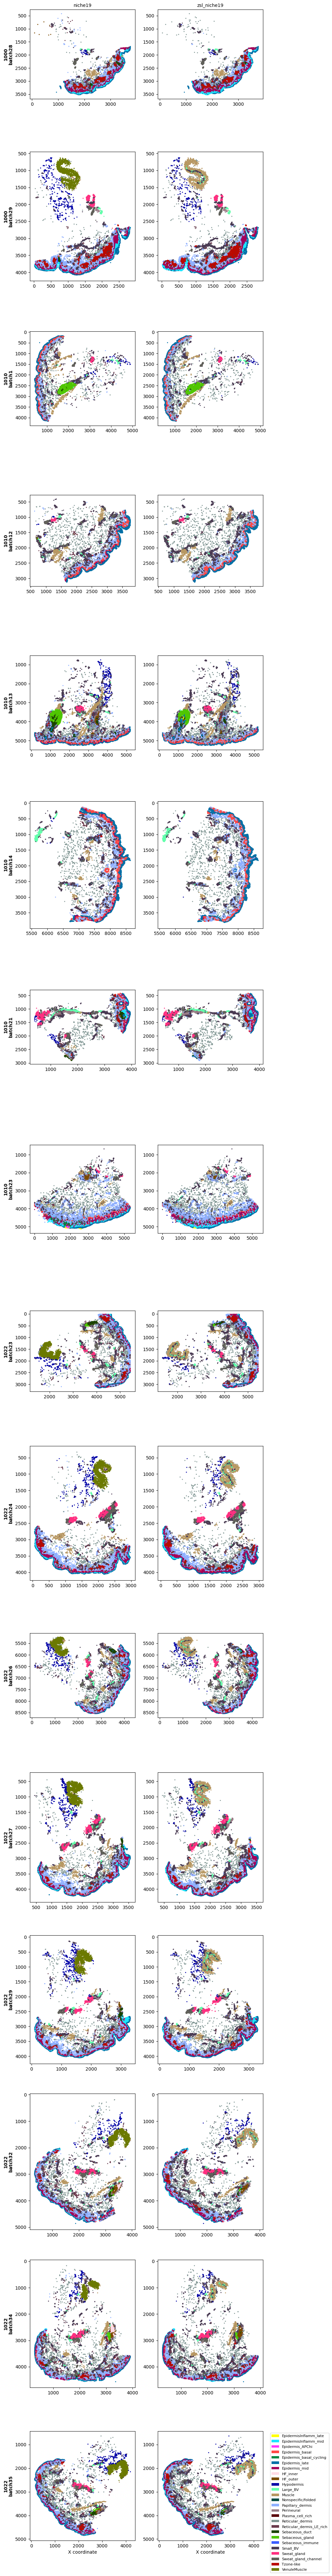

In [14]:
# Plot spatial comparison with dataset_id + batch rows
fig, axes = plot_spatial_comparison(
    adata=test_adata,
    column_names=['niche19', 'zsl_niche19'],
    spatial_key='spatial',
    dataset_id_col='dataset_id',
    batch_col='batch',
    spot_size=5,
    save_path=None
)

plt.show()